<a href="https://colab.research.google.com/github/Yasmin-maker1/Automated-Classification-of-White-Blood-Cell-Subtypes-Using-Convolutional-Neural-Networks/blob/main/notebooks/final_defense_annotated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# White blood cell classification — final code walkthrough (annotated)

Group 4 · Yasmin Rocio Orduz Landazabal, Matthew Ragsdale · CSCI 7090, Fall 2026

Every code block is printed **straight from `src/`**, the code we submitted, and every result is **loaded from the
saved run outputs on Google Drive**. Nothing is retrained except one short live run (cell 5c) that shows the training
loop works.

Each code cell has a note above it: **what the cell does** and **what it means for our project**. The code cells
themselves are the same as in `notebooks/final_defense.ipynb`.

| Section | What it shows | Time |
|---|---|---|
| 0 | Setup | 0:10 |
| 1 | Data | 0:25 |
| 2 | Finding the leak: matching each image to its original photo | 1:10 |
| 3 | The group split | 0:45 |
| 4 | Models | 0:35 |
| 5 | Training recipe and the live run | 0:30 |
| 6 | Validation comparison (3 seeds) | 0:40 |
| 7 | Test results, full and clean subset | 0:50 |
| 8 | Error analysis | 0:40 |
| 9 | Grad-CAM | 0:25 |
| 10 | Ablations: augmentation, aspect ratio | 0:20 |
| | **Total** | **6:30** |

How to read the tags on each note:

- **STOP**: stay on this output and explain it.
- **SCROLL**: show it for a few seconds while talking, do not read it.
- **SKIP**: do not present; it is there for questions.

**Before the presentation:** Runtime → Change runtime type → T4 GPU, then Runtime → Run all once, so every output is
already on screen. During the walkthrough, scroll and explain; re-run a single cell only if asked.

## 0. Setup

**Cell 0a · SKIP · 0:10 in total for section 0** — get the code, find the saved results

- **What it does.** Clones our GitHub repository and prints the commit it is running. Mounts Google Drive and checks that three things exist: the split file, the folder with the 21 training runs, and the folder with the split figures. Imports our own modules from `src/`. Defines `show()`, which prints the real source of a function together with its file name and line number.
- **What it means for our project.** Two guarantees for the defense. The code on screen is the submitted code, not a copy typed into the notebook. The numbers on screen are read from the saved runs, so they are the same numbers as in the slides. Three lines starting with `ok` mean the saved results were found.
- **If asked.** `%matplotlib inline` is at the end because our scripts switch matplotlib to a file-only mode; this line switches figures back on inside the notebook.

In [1]:
import os, sys, json, inspect, importlib
from IPython.display import Image as IPImage, Markdown, display
import pandas as pd

REPO_URL = "https://github.com/Yasmin-maker1/Automated-Classification-of-White-Blood-Cell-Subtypes-Using-Convolutional-Neural-Networks.git"
if os.path.exists("/content/repo/.git"):
    %cd /content/repo
    !git pull -q
else:
    !git clone -q {REPO_URL} /content/repo
    %cd /content/repo
!git log -1 --format="code version: %h  %s  (%cd)"

from google.colab import drive
drive.mount("/content/drive")
DRIVE = "/content/drive/MyDrive/wbc_project"
SPLIT = f"{DRIVE}/group_split.json"                 # made by src/group_split.py
EXP   = f"{DRIVE}/experiments_groupsplit"           # made by src/run_experiments.py
GS    = f"{DRIVE}/group_split"                      # figures + tables from group_split.py
for p in (SPLIT, EXP, GS):
    print(("ok      " if os.path.exists(p) else "MISSING ") + p)

sys.path.insert(0, "/content/repo/src")
import data, model, train, evaluate, group_split, run_experiments, gradcam, error_analysis

def show(obj):
    """Print the real source code of a function or class from src/."""
    obj = inspect.unwrap(obj)   # look through decorators such as @torch.no_grad()
    src = inspect.getsource(obj)
    file = inspect.getsourcefile(obj).split("/repo/")[-1]
    line = inspect.getsourcelines(obj)[1]
    display(Markdown(f"`{file}`, line {line}\n```python\n{src}\n```"))

%matplotlib inline

/content/repo
code version: 88045f5  Add files via upload  (Wed Nov 18 10:33:52 2026 -0500)
Mounted at /content/drive
ok      /content/drive/MyDrive/wbc_project/group_split.json
ok      /content/drive/MyDrive/wbc_project/experiments_groupsplit
ok      /content/drive/MyDrive/wbc_project/group_split


**Cell 0b · SKIP** — the images

- **What it does.** Downloads the Kaggle dataset if it is not on this machine yet (it asks for `kaggle.json`). `data.find_split_dirs` then searches for the `TRAIN` and `TEST` folders that hold the four class folders.
- **What it means for our project.** The images are only needed for the two live parts: one training epoch (5c) and one Grad-CAM example (9b). Everything else is loaded from Drive. The folder `TEST_SIMPLE` is ignored on purpose, as in the proposal.

In [2]:
if not os.path.exists("data/dataset2-master"):
    from google.colab import files
    files.upload()   # kaggle.json
    !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
    !pip -q install kaggle
    !kaggle datasets download -d paultimothymooney/blood-cells -p data --unzip
train_dir, test_dir = data.find_split_dirs("data")
print("TRAIN:", train_dir, "\nTEST :", test_dir)

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/blood-cells
License(s): other
100% 108M/108M [00:01<00:00, 112MB/s]  

TRAIN: data/dataset2-master/dataset2-master/images/TRAIN 
TEST : data/dataset2-master/dataset2-master/images/TEST


## 1. Data

Kaggle *Blood Cell Images* (Mooney, 2018): 9,957 TRAIN + 2,487 TEST images, 4 balanced classes, all 320×240.
Every image is a rotated/flipped/shifted copy of one of **366 original photos** (`dataset-master/JPEGImages`), which
is why the black corners appear, and why a random split leaks.

**Cell 1a · STOP · 0:25** — class counts and one image per class

- **What it does.** Counts the images of each class in the `TRAIN` and `TEST` folders, then shows the first training image of each class.
- **What it means for our project.** 9,957 training and 2,487 test images, 12,444 in total, about 25% per class. Because the classes are balanced we need no class weights, and accuracy and macro-F1 tell a similar story. Each picture is a wide field with many red cells and one white cell. The black corners on rotated images are the first sign that these are copies of a smaller set of photos.
- **If asked.** Three counts differ slightly from Table 1 of the proposal (monocyte train 2,478, eosinophil test 623, neutrophil test 624). These are the real counts on disk.

TRAIN {'EOSINOPHIL': 2497, 'LYMPHOCYTE': 2483, 'MONOCYTE': 2478, 'NEUTROPHIL': 2499} total 9957
TEST {'EOSINOPHIL': 623, 'LYMPHOCYTE': 620, 'MONOCYTE': 620, 'NEUTROPHIL': 624} total 2487


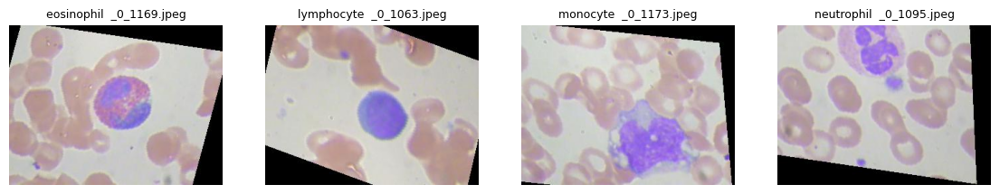

In [3]:
from torchvision import datasets
for name, d in (("TRAIN", train_dir), ("TEST", test_dir)):
    ds = datasets.ImageFolder(d)
    print(name, {c: ds.targets.count(i) for i, c in enumerate(ds.classes)}, "total", len(ds))

import matplotlib.pyplot as plt
from PIL import Image
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, c in zip(axes, sorted(os.listdir(train_dir))):
    f = sorted(os.listdir(f"{train_dir}/{c}"))[0]
    ax.imshow(Image.open(f"{train_dir}/{c}/{f}")); ax.set_title(f"{c.lower()}  {f}", fontsize=9); ax.axis("off")
plt.show()

## 2. Finding the leak — `src/group_split.py`

**Midterm feedback:** the near-duplicate check was not rotation-aware, and validation was saturated.

**What changed:** instead of comparing augmented images with each other, every image is matched back to the
**original photo** it was made from. Each original is rendered in 144 views (2 flips × a rotation every 5°, with the
same black corners), and each image goes to the photo whose best view is most similar. The *margin* over the
second-best photo says how sure the match is.

**Cell 2a · STOP · 0:35** — the matching code

- **What it does.** Prints two functions. `embed_original_views` takes each of the 366 original photos, makes 144 views of it (2 flips × 72 rotations, one every 5°, with black corners like the Kaggle images), and turns every view into a feature vector with an ImageNet ResNet-50. `match_to_originals` compares every Kaggle image with all views of all photos. `s.max(dim=2)` keeps the best view of each photo, and `topk(2)` keeps the best and the second-best photo. The best photo is the source; best minus second-best is the **margin**.
- **What it means for our project.** This is our answer to the midterm feedback that the check was not rotation-aware. At the midterm we compared Kaggle images with each other, upright only, so a rotated copy looked like a different image. Now every image is traced back to the photo it came from, whatever its rotation or flip.
- **If asked.** The features are normalised, so the matrix product `@` is a cosine similarity. Only the centre of the frame is compared, because a rotation never cuts that part off.

In [4]:
show(group_split.embed_original_views)
show(group_split.match_to_originals)

`src/group_split.py`, line 203
```python
@torch.no_grad()
def embed_original_views(paths, model, device, img_size, angles, batch_size, num_workers, use_amp):
    """Returns (n_originals, n_views, D) and the list of (flip, angle) for each view."""
    views = [(flip, ang) for flip in (False, True) for ang in angles]
    loader = DataLoader(OriginalsDataset(paths), batch_size=max(1, batch_size // 8), shuffle=False,
                        num_workers=num_workers)
    out = []
    for x in loader:
        x = x.to(device)
        per_view = []
        for flip, ang in views:
            v = TF.hflip(x) if flip else x
            if ang:
                v = TF.rotate(v, float(ang), interpolation=TF.InterpolationMode.BILINEAR, fill=[0.0, 0.0, 0.0])
            v = TF.resize(v, [img_size, img_size], antialias=True)
            per_view.append(embed(model, normalise(v), use_amp))
        out.append(torch.stack(per_view, dim=1).cpu())  # (b, V, D)
    return torch.cat(out), views

```

`src/group_split.py`, line 223
```python
def match_to_originals(aug, orig_views, device, chunk=256):
    """For every augmented image: best original, its best view, similarity, and margin to the runner-up."""
    n_orig, n_views, dim = orig_views.shape
    ref = orig_views.reshape(n_orig * n_views, dim).to(device)
    best, best_view, sim1, sim2 = [], [], [], []
    for i in range(0, len(aug), chunk):
        s = (aug[i:i + chunk].to(device) @ ref.T).view(-1, n_orig, n_views)
        s_orig, v_idx = s.max(dim=2)                                    # best view per original
        top = s_orig.topk(min(2, n_orig), dim=1)
        best.append(top.indices[:, 0].cpu())
        sim1.append(top.values[:, 0].cpu())
        sim2.append((top.values[:, 1] if n_orig > 1 else torch.zeros_like(top.values[:, 0])).cpu())
        best_view.append(v_idx.gather(1, top.indices[:, :1]).squeeze(1).cpu())
    return (torch.cat(best).numpy(), torch.cat(best_view).numpy(),
            torch.cat(sim1).numpy(), torch.cat(sim2).numpy())

```

How good is the matching? The check is independent: does the matched photo's label in `labels.csv` agree with the image's class folder?

**Cell 2b · STOP · 0:35** — how good is the matching, and the leak seen by eye

- **What it does.** Loads the summary stored in the split file. Prints the label agreement overall and per class, the margin threshold, and a table of margin bands marked `kept` or `excluded`. Then shows three figures: random matches, test images whose photo is also in train, and the weakest matches we kept.
- **What it means for our project.** We have no ground truth for which photo an image came from, so we use an independent check: does the matched photo's label in `labels.csv` agree with the image's class folder? It agrees for 97.4% of images. Below a margin of 0.02 the agreement falls to 55–81%, so those 783 training images are left out instead of risking a leak. Above 0.02 it is 97.5–100%. The second figure is the leak itself: on the left a test image, on the right the original photo it came from, and that photo also produced training images. The second and third rows are the clearest examples.
- **If asked.** 353 of the 366 photos are used. The threshold 0.02 was chosen from this table, before any model was trained on the new split.

Label agreement overall: 97.4%   by class: {'EOSINOPHIL': 0.9763, 'LYMPHOCYTE': 0.9726, 'MONOCYTE': 0.9632, 'NEUTROPHIL': 0.9843}
Unsure threshold (margin): 0.02    photos used: 353 of 366


,images,label_agreement,used
0.000-0.005,331.0,0.5529,excluded
0.005-0.010,208.0,0.7212,excluded
0.010-0.020,416.0,0.8125,excluded
0.020-0.050,1452.0,0.9752,kept
0.050-1.000,10037.0,0.9998,kept


random_matches.png


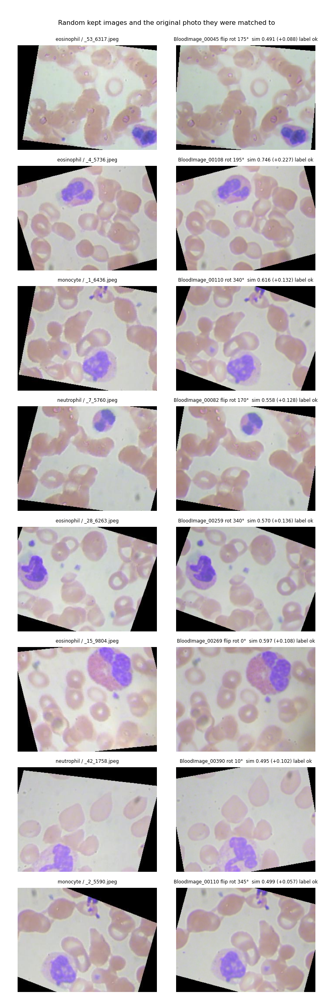

test_overlap_examples.png


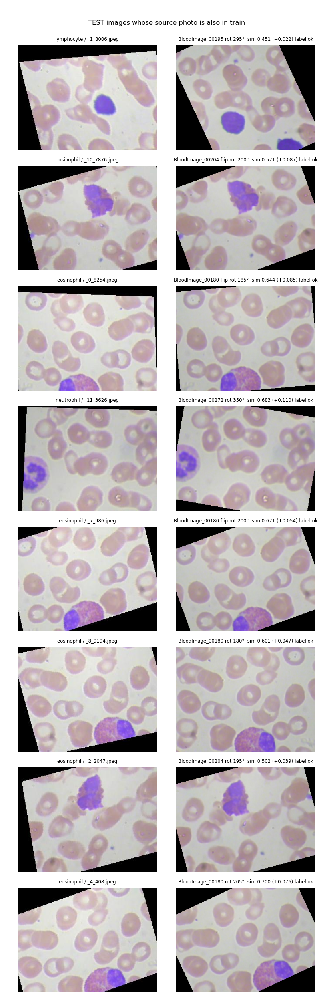

weakest_kept_matches.png


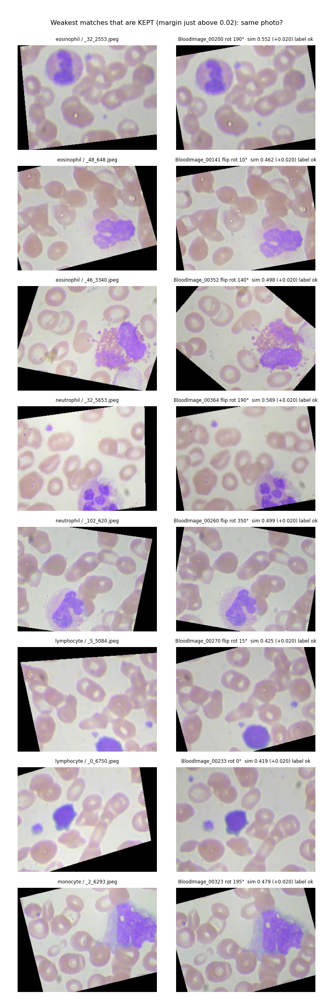

In [5]:
s = json.load(open(SPLIT))
summ = s["summary"]
print(f"Label agreement overall: {summ['label_agreement']:.1%}   by class: {summ['label_agreement_by_class']}")
print(f"Unsure threshold (margin): {summ['min_margin']}    photos used: {summ['unsure']['photos_used']} of {summ['unsure']['photos_available']}")
bands = pd.DataFrame(summ["by_margin_band"]).T
bands["used"] = ["excluded" if float(b.split("-")[1]) <= summ["min_margin"] else "kept" for b in bands.index]
display(bands)
for f in ["random_matches.png", "test_overlap_examples.png", "weakest_kept_matches.png"]:
    print(f); display(IPImage(f"{GS}/{f}"))

## 3. The group split

Train and validation are split **by photo** with `StratifiedGroupKFold`, so no photo is on both sides. Unsure matches
are left out of train and validation, and a test image only counts as *clean* if its photo is not in train and its
match is sure. The official TEST folder is never used for any decision.

**Cell 3a · STOP · 0:20** — the split code

- **What it does.** `group_train_val` runs scikit-learn's `StratifiedGroupKFold` with the source photo as the group, and keeps the fold whose size is closest to 20% and whose class mix is closest to the whole set. `split_from_file` is how training reads that split: it looks up every image in the file, returns the train and validation indices, and returns the indices of the clean test images.
- **What it means for our project.** *Group* means all copies of one photo go to the same side, so validation never sees a photo that training saw. *Stratified* keeps the four classes balanced on both sides. `split_from_file` raises an error if any image is missing from the file, so a run can never fall back to the old random split without us noticing.

In [6]:
show(group_split.group_train_val)
show(data.split_from_file)

`src/group_split.py`, line 243
```python
def group_train_val(classes, groups, val_frac, seed):
    """StratifiedGroupKFold; keep the fold closest to val_frac with the most similar class mix."""
    n_splits = max(2, round(1 / val_frac))
    classes, groups = np.asarray(classes), np.asarray(groups)
    overall = np.bincount(classes, minlength=classes.max() + 1) / len(classes)
    best, best_score = None, np.inf
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for tr, va in sgkf.split(np.zeros(len(classes)), classes, groups):
        mix = np.bincount(classes[va], minlength=len(overall)) / len(va)
        score = abs(len(va) / len(classes) - val_frac) + np.abs(mix - overall).sum()
        if score < best_score:
            best, best_score = (np.sort(tr), np.sort(va)), score
    return best

```

`src/data.py`, line 137
```python
def split_from_file(split_file, train_samples, test_samples, train_dir, test_dir):
    """Read a group_split.py file -> (train_idx, val_idx, clean_test_idx)."""
    spec = json.loads(Path(split_file).read_text())["images"]

    def keys(prefix, root, samples):
        return [f"{prefix}/{Path(os.path.relpath(p, root)).as_posix()}" for p, _ in samples]

    k_train, k_test = keys("TRAIN", train_dir, train_samples), keys("TEST", test_dir, test_samples)
    missing = [k for k in k_train + k_test if k not in spec]
    if missing:
        raise RuntimeError(f"{len(missing)} images are not in the split file {split_file} (e.g. {missing[:3]}). "
                           f"It was made for different data: rerun src/group_split.py.")
    split = np.array([spec[k]["split"] for k in k_train])
    if set(split) - {"train", "val", "excluded"}:   # excluded = source photo too uncertain to place safely
        raise RuntimeError(f"Unexpected split labels in {split_file}: {sorted(set(split))}")
    train_idx, val_idx = np.where(split == "train")[0], np.where(split == "val")[0]
    clean_test_idx = np.array([i for i, k in enumerate(k_test) if not spec[k]["source_in_train"]], dtype=int)
    return train_idx, val_idx, clean_test_idx

```

**Cell 3b · STOP · 0:25** — the split in numbers

- **What it does.** Shows, per class, how many images and photos are in train, validation, excluded and test. Then prints two lines: the share of validation images whose photo is also in train (old split, new split), and the same check for the test folder.
- **What it means for our project.** **99.9% → 0.0%** is the main fix of the project: with the midterm split almost every validation image had its photo in training, which is why validation reached 100%. Final sizes: 7,436 train, 1,738 validation, 783 excluded. The test folder has 2,487 images from only 113 photos; 170 images (6.8%) share a photo with train, so we also report a **clean subset of 2,205 images**.
- **If asked.** Validation has only 4 lymphocyte photos and 6 monocyte photos. That is how the dataset was built, no split can change it, and it is why validation is noisier than its image count suggests.

In [7]:
display(pd.read_csv(f"{GS}/per_class_sources.csv"))
v, t = summ["val_sharing_photo_with_train"], summ["test"]
print(f"Validation images whose photo is also in train: random split {v['random_split']:.1%}  ->  group split {v['group_split']:.1%}")
print(f"TEST: {t['n']} images from {t['n_photos']} photos; {t['n_photo_in_train']} ({t['n_photo_in_train']/t['n']:.1%}) "
      f"come from {t['photos_shared_with_train']} photos also in train; {t['n_unsure']} unsure -> clean subset {t['n_clean']} images")

,class,train imgs,train photos,val imgs,val photos,excluded (unsure),test imgs,test photos,test clean
0,eosinophil,1843,65,489,16,165,623,35,489
1,lymphocyte,1958,29,333,4,192,620,17,580
2,monocyte,1840,21,447,6,191,620,16,588
3,neutrophil,1795,131,469,34,235,624,64,548


Validation images whose photo is also in train: random split 99.9%  ->  group split 0.0%
TEST: 2487 images from 113 photos; 170 (6.8%) come from 37 photos also in train; 172 unsure -> clean subset 2205 images


## 4. Models — `src/model.py`

Same 4-way head replacement for every pretrained network; the head is always called `fc` or `classifier`, so one
function freezes any backbone.

**Cell 4a · STOP · 0:20** — the four models

- **What it does.** `build_model` loads each pretrained network with ImageNet weights and replaces only its last layer with a new 4-output linear layer (ResNet-50: 2048 → 4, EfficientNet-B0: 1280 → 4, DenseNet-169: 1664 → 4). The SmallCNN is our own network, trained from scratch: four blocks of convolution, batch norm, ReLU and max-pooling, then global average pooling, dropout and one linear layer. `set_backbone_trainable` freezes every parameter except the new head.
- **What it means for our project.** All four models share one interface, so the comparison is fair: the same data, loop and settings, and only the backbone changes. The freeze function gives us two things from the plan: the 2 head-only warm-up epochs, and the full frozen-backbone run promised at the midterm.
- **If asked.** The loss applies the softmax, so the models output raw scores (logits).

In [8]:
show(model.build_model)
show(model.set_backbone_trainable)

`src/model.py`, line 47
```python
def build_model(name: str = "resnet50", num_classes: int = 4, pretrained: bool = True) -> nn.Module:
    name = name.lower()
    if name == "resnet50":
        weights = ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
        model = resnet50(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model
    if name == "efficientnet_b0":
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
        model = efficientnet_b0(weights=weights)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        return model
    if name == "densenet169":
        weights = DenseNet169_Weights.IMAGENET1K_V1 if pretrained else None
        model = densenet169(weights=weights)
        model.classifier = nn.Linear(model.classifier.in_features, num_classes)
        return model
    if name == "smallcnn":
        return SmallCNN(num_classes)
    raise ValueError(f"Unknown model '{name}'. Choose one of {MODEL_NAMES}.")

```

`src/model.py`, line 69
```python
def set_backbone_trainable(model: nn.Module, trainable: bool) -> None:
    """Freeze/unfreeze everything except the classification head."""
    for pname, p in model.named_parameters():
        is_head = pname.startswith(HEAD_PREFIXES)
        p.requires_grad = True if is_head else trainable

```

**Cell 4b · SCROLL · 0:15** — model sizes

- **What it does.** Builds each model without downloading weights, freezes the backbone, and counts the parameters.
- **What it means for our project.** The sizes behind the result: ResNet-50 23.5 M, DenseNet-169 12.5 M, EfficientNet-B0 4.0 M, SmallCNN 0.4 M. With the backbone frozen, only the head trains: 8,196 parameters for ResNet-50, 5,124 for EfficientNet-B0, 6,660 for DenseNet-169. Keep these in mind for section 7, where the smallest model ties the largest.
- **If asked.** The table also shows a frozen count for the SmallCNN (its last layer, 1,028). That is only what the function would leave trainable; the SmallCNN is never frozen in our runs, it always trains in full.

In [9]:
rows = []
for name in model.MODEL_NAMES:
    m = model.build_model(name, 4, pretrained=False)
    model.set_backbone_trainable(m, False)
    p = model.count_parameters(m)
    rows.append({"model": name, "parameters (M)": round(p["total"] / 1e6, 2), "trainable when frozen": p["trainable"]})
display(pd.DataFrame(rows))

,model,parameters (M),trainable when frozen
0,resnet50,23.52,8196
1,efficientnet_b0,4.01,5124
2,densenet169,12.49,6660
3,smallcnn,0.39,1028


## 5. Training recipe — `src/train.py`, `src/run_experiments.py`

One recipe for every model: Adam, head lr 1e-3, backbone lr 1e-4, weight decay 1e-4, batch 64, 2 head-only epochs then
full fine-tuning, early stopping on validation loss (patience 3), best checkpoint = lowest validation loss. Only the
backbone changes between runs. The split is fixed (`--split-seed 42`); `--seed` (42, 43, 44) changes initialisation,
data order and augmentation.

**Cell 5a · SCROLL · 0:10** — the training loop and the list of runs

- **What it does.** `run_epoch` is one pass over the data and is used for both training and validation. With an optimizer it trains: forward pass, cross-entropy loss, backward pass, update. Without one it only measures, with gradients switched off. It returns the mean loss and the accuracy. `build_grid` writes the list of runs: for each seed, three fine-tuned backbones, one frozen ResNet-50 and one SmallCNN, plus the two ablations.
- **What it means for our project.** One loop for every model is what makes the comparison fair. The grid is the experiment plan in code: 5 configurations × 3 seeds = 15 runs, plus 2 ablations × 3 seeds = 6 runs, 21 in total.
- **If asked.** `freeze_bn` keeps the BatchNorm statistics fixed while the backbone is frozen. `autocast` and the scaler are mixed precision, which only makes training faster on the T4.

In [10]:
show(train.run_epoch)
show(run_experiments.build_grid)

`src/train.py`, line 72
```python
def run_epoch(model, loader, criterion, device, optimizer=None, scaler=None,
              use_amp=False, freeze_bn=False):
    training = optimizer is not None
    model.train(training)
    if training and freeze_bn:
        freeze_batchnorm(model)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(x)
                loss = criterion(logits, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                if scaler is not None:
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

```

`src/run_experiments.py`, line 64
```python
def build_grid(a):
    """List of (run_name, model, extra train.py flags, seed, epochs, freeze_epochs)."""
    grid = []
    for seed in a.seeds:
        if not a.only_ablations:
            for m in a.finetune_models:
                grid.append((f"{m}_ft_s{seed}", m, [], seed, a.epochs, a.freeze_epochs))
            for m in a.frozen_models:
                grid.append((f"{m}_frozen_s{seed}", m, [], seed, a.epochs, a.epochs))
            if not a.no_baseline:
                grid.append((f"smallcnn_scratch_s{seed}", "smallcnn", [], seed, a.baseline_epochs, 0))
        if a.ablations or a.only_ablations:
            grid.append((f"smallcnn_noaug_s{seed}", "smallcnn", ["--no-augment"], seed, a.baseline_epochs, 0))
            grid.append((f"smallcnn_pad_s{seed}", "smallcnn", ["--resize", "pad"], seed, a.baseline_epochs, 0))
    return grid

```

**Cell 5b · STOP · 0:10** — the recipe, read from a real run

- **What it does.** Opens the `config.json` saved by one real run (DenseNet-169, seed 42) and prints its settings and the number of train, validation and test images.
- **What it means for our project.** Proof that the recipe on our slide is what actually ran: Adam, head learning rate 1e-3, backbone 10× smaller, weight decay 1e-4, batch 64, 2 head-only epochs, at most 15 epochs, early stopping with patience 3, image size 224, squash resize, augmentation on. The image counts 7,436 / 1,738 / 2,487 match the split in section 3.
- **If asked.** `seed` changes the initial weights, the data order and the augmentation. `split_seed` stays at 42, so every run sees exactly the same images.

In [11]:
cfg = json.load(open(f"{EXP}/densenet169_ft_s42/config.json"))
keep = ["model", "epochs", "freeze_epochs", "batch_size", "lr", "backbone_lr_mult", "weight_decay", "patience",
        "seed", "split_seed", "split_file", "img_size", "resize", "no_augment", "amp"]
defaults = {"resize": "squash", "no_augment": False}   # runs made before these options existed used these
display(pd.Series({k: cfg["args"].get(k, defaults.get(k)) for k in keep}, name="densenet169_ft_s42 config"))
print("train / val / test images:", cfg["n_train"], cfg["n_val"], cfg["n_test"])

,densenet169_ft_s42 config
model,densenet169
epochs,15
freeze_epochs,2
batch_size,64
lr,0.001
backbone_lr_mult,0.1
weight_decay,0.0001
patience,3
seed,42
split_seed,42


train / val / test images: 7436 1738 2487


**Live proof that the pipeline runs end to end:** 1 epoch of the SmallCNN on the group split (about 1 minute on a T4). Not a reported result.

**Cell 5c · SCROLL · 0:10** — one live training epoch

- **What it does.** Runs `src/train.py` for one epoch of the SmallCNN on the group split, about one minute on a T4. The output goes to a separate folder, not to the results on Drive.
- **What it means for our project.** It shows that the code on GitHub runs from start to finish today. It is **not** a result: after one epoch the accuracy is far below the final model. Point at two printed lines: `split=group split ...` and `train=7436  val=1738  test(not touched)=2487`.

In [12]:
!python src/train.py --data-root data --model smallcnn --epochs 1 --split-file {SPLIT} --amp --num-workers 2 \
    --out-dir /content/live_demo --run-name smallcnn_live_1epoch

device=cuda  amp=True  classes=['eosinophil', 'lymphocyte', 'monocyte', 'neutrophil']
split=group split /content/drive/MyDrive/wbc_project/group_split.json  resize=squash  augmentation=on
train=7436  val=1738  test(not touched)=2487
-- epoch 1: backbone TRAINABLE (389,924 trainable params)
epoch 01/1  train 1.2260/0.4338  val 0.9673/0.6041  (63s)

Done in 1.1 min. Best epoch 1: val loss 0.9673, val acc 0.6041
Saved to /content/live_demo/smallcnn_live_1epoch/   ->  next: python src/evaluate.py --checkpoint /content/live_demo/smallcnn_live_1epoch/best.pt


## 6. Validation comparison (3 seeds each, mean ± sample std)

Selection rule, fixed before looking at the test set: **lowest mean validation loss**.

**Cell 6a · STOP · 0:40** — choosing the model on validation

- **What it does.** Loads `summary.csv`, made by `src/aggregate_runs.py`: the mean ± standard deviation over the three seeds for each configuration. Shows the validation columns, then the training curves of four runs.
- **What it means for our project.** Model selection happens here and only here, before the test set is opened. The SmallCNN has the lowest mean validation loss (0.225 ± 0.011), so it is the selected model. In the curves, the fine-tuned networks are best at epoch 3–6 and then their validation loss rises while training loss keeps falling: overfitting that the leaky split had hidden. The frozen ResNet-50 levels off near 71% validation accuracy, so ImageNet features alone do not separate these cells.
- **If asked.** We select on loss, not accuracy, because the rule was fixed in advance and loss also uses how confident each prediction is. Section 10 shows a case where accuracy would have picked the wrong model.

,configuration,seeds,params (M),val loss,val acc,best epoch,min / run
0,densenet169 (fine-tuned),3,12.5,0.2751 ± 0.0247,0.9066 ± 0.0052,4.0 ± 1.0,7.2 ± 1.1
1,efficientnet_b0 (fine-tuned),3,4.0,0.2616 ± 0.0300,0.8999 ± 0.0158,3.0 ± 0.0,5.6 ± 0.1
2,resnet50 (frozen),3,23.5,0.6538 ± 0.0055,0.7125 ± 0.0043,13.3 ± 1.2,13.3 ± 0.1
3,resnet50 (fine-tuned),3,23.5,0.2929 ± 0.0160,0.9129 ± 0.0119,6.0 ± 4.4,8.6 ± 4.2
4,"smallcnn (scratch, no augmentation)",3,0.4,0.3948 ± 0.1155,0.8586 ± 0.0136,4.3 ± 1.5,3.1 ± 0.7
5,"smallcnn (scratch, pad resize)",3,0.4,0.2769 ± 0.0689,0.9379 ± 0.0137,6.0 ± 3.5,7.8 ± 3.0
6,smallcnn (scratch),3,0.4,0.2248 ± 0.0109,0.9166 ± 0.0080,11.0 ± 2.6,12.2 ± 2.2


smallcnn_scratch_s42


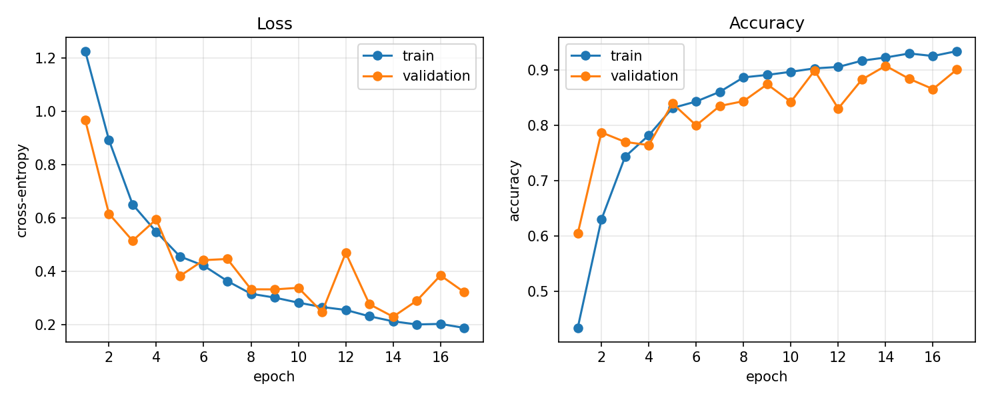

resnet50_ft_s42


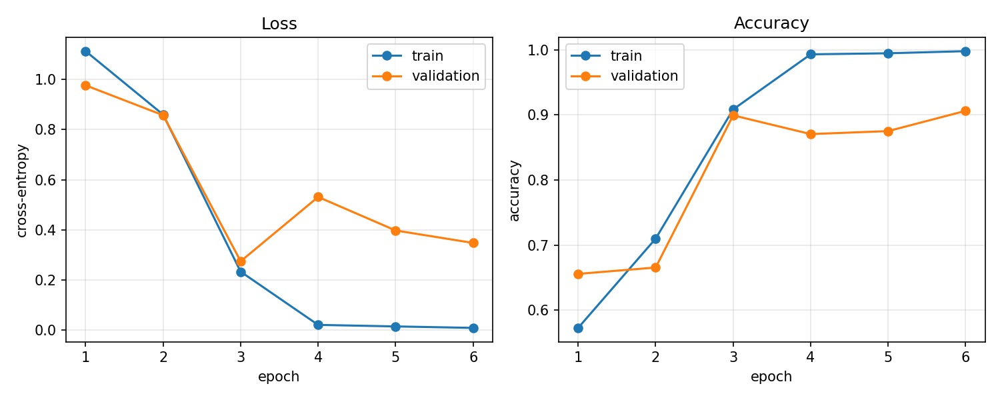

densenet169_ft_s42


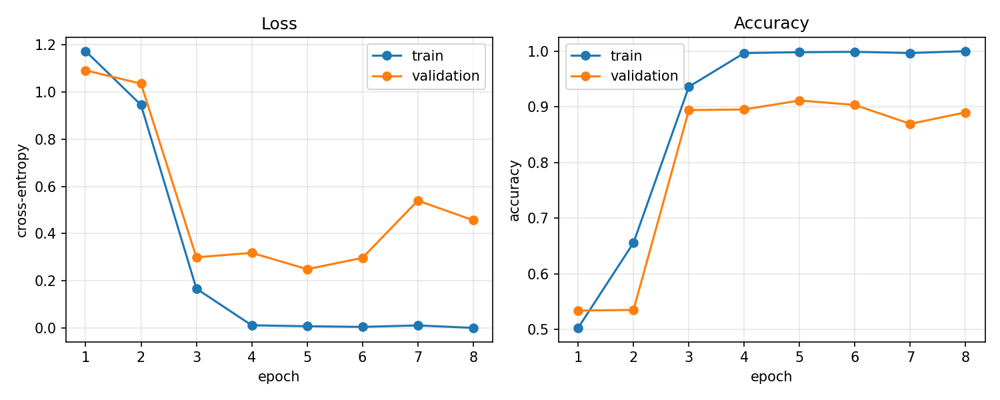

resnet50_frozen_s42


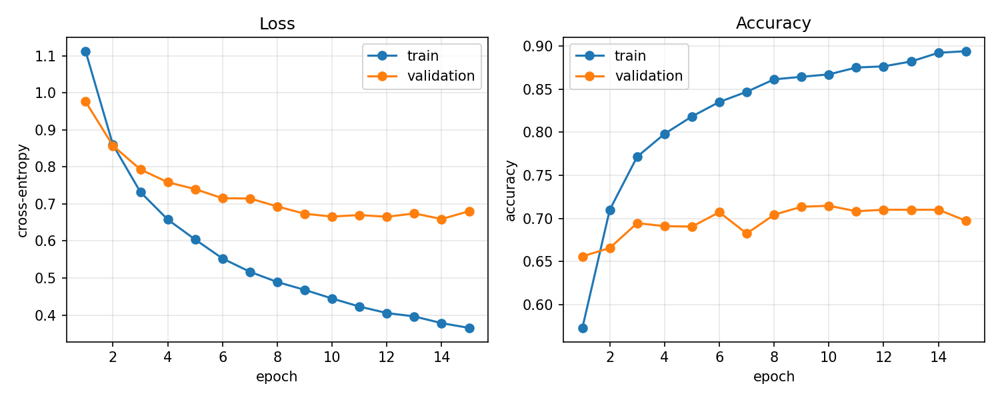

In [13]:
summary = pd.read_csv(f"{EXP}/summary.csv")
display(summary[["configuration", "seeds", "params (M)", "val loss", "val acc", "best epoch", "min / run"]])
for run in ["smallcnn_scratch_s42", "resnet50_ft_s42", "densenet169_ft_s42", "resnet50_frozen_s42"]:
    print(run); display(IPImage(f"{EXP}/{run}/curves.png", width=800))

## 7. Test results — `src/evaluate.py`

Every saved model was evaluated **once** on the TEST folder (no decision changed afterwards). *Clean test* = the
2,205 test images whose source photo is not in train.

**Cell 7a · SCROLL · 0:10** — the evaluation code

- **What it does.** Prints `evaluate.main`. It loads a saved checkpoint, rebuilds the data with the same split file, predicts the test folder once, and computes accuracy, per-class precision, recall and F1, macro-F1 and the confusion matrix. It saves every prediction to `predictions.csv`.
- **What it means for our project.** Scroll to the block that starts with `clean = data["clean_test_idx"]`. That block repeats the metrics on the test images whose photo was never in training. It is how we report a number that the 6.8% overlap cannot inflate.
- **If asked.** Macro-F1 is the plain average of the four per-class F1 scores, so a weak class cannot hide behind the strong ones.

In [14]:
show(evaluate.main)

`src/evaluate.py`, line 86
```python
def main(argv=None):
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--checkpoint", required=True)
    p.add_argument("--data-root", default=None, help="defaults to the one used for training")
    p.add_argument("--batch-size", type=int, default=64)
    p.add_argument("--num-workers", type=int, default=4)
    p.add_argument("--out-dir", default=None, help="defaults to <checkpoint folder>/eval")
    p.add_argument("--split-file", default=None,
                   help="defaults to the one used for training; enables the clean-test-subset numbers")
    a = p.parse_args(argv)

    device = get_device()
    ckpt = torch.load(a.checkpoint, map_location="cpu", weights_only=False)
    targs = ckpt["args"]
    classes = ckpt["classes"]
    out_dir = Path(a.out_dir) if a.out_dir else Path(a.checkpoint).parent / "eval"
    out_dir.mkdir(parents=True, exist_ok=True)

    split_file = a.split_file or targs.get("split_file")
    data = build_datasets(a.data_root or targs["data_root"], targs["img_size"], targs["val_frac"],
                          targs.get("split_seed", targs["seed"]), split_file, resize=targs.get("resize", "squash"))
    if data["classes"] != classes:
        raise RuntimeError("Class order in the data differs from the checkpoint.")
    test_loader = make_loader(data["test"], a.batch_size, False, a.num_workers, targs["seed"])

    model = build_model(ckpt["model_name"], len(classes), pretrained=False)
    model.load_state_dict(ckpt["model_state"])
    model.to(device)

    probs, y_true = predict_loader(model, test_loader, device)
    y_pred = probs.argmax(1)
    conf = probs.max(1)

    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=range(len(classes)), zero_division=0)
    macro_f1 = float(np.mean(f1))
    top2 = float(np.mean([y_true[i] in np.argsort(-probs[i])[:2] for i in range(len(y_true))]))
    cm = confusion_matrix(y_true, y_pred, labels=range(len(classes)))

    # most common confusions (off-diagonal cells), incl. the pair the proposal cares about
    confusions = [(classes[i], classes[j], int(cm[i, j])) for i in range(len(classes))
                  for j in range(len(classes)) if i != j and cm[i, j] > 0]
    confusions.sort(key=lambda t: -t[2])
    mono, lymph = classes.index("monocyte"), classes.index("lymphocyte")
    mono_lymph = int(cm[mono, lymph] + cm[lymph, mono])

    per_class = pd.DataFrame({"class": classes, "precision": prec, "recall": rec, "f1": f1, "support": support})
    per_class.to_csv(out_dir / "per_class.csv", index=False)
    (out_dir / "classification_report.txt").write_text(
        classification_report(y_true, y_pred, target_names=classes, digits=4, zero_division=0))
    paths = [s[0] for s in data["test"].samples]
    pd.DataFrame({"path": paths, "true": [classes[i] for i in y_true], "pred": [classes[i] for i in y_pred],
                  "confidence": conf, **{f"p_{c}": probs[:, k] for k, c in enumerate(classes)}}
                 ).to_csv(out_dir / "predictions.csv", index=False)
    plot_confusion(cm, classes, out_dir / "confusion_matrix.png", ckpt["model_name"])
    n_err = plot_errors(paths, y_true, y_pred, conf, classes, out_dir / "misclassified.png")

    metrics = {"model": ckpt["model_name"], "checkpoint": str(a.checkpoint), "n_test": int(len(y_true)),
               "accuracy": acc, "macro_f1": macro_f1, "top2_accuracy": top2,
               "monocyte_lymphocyte_confusions": mono_lymph,
               "top_confusions": confusions[:5],
               "baseline_praveen_2021": PRAVEEN_BASELINE, "meets_baseline": bool(acc >= PRAVEEN_BASELINE)}
    clean = data["clean_test_idx"]
    if clean is not None:
        metrics["split_file"] = split_file
        metrics["clean_subset"] = {"n": int(len(clean)), "note": "test images whose source photo is not in train"}
        if len(clean):
            yc, pc = y_true[clean], y_pred[clean]
            _, _, f1c, supc = precision_recall_fscore_support(yc, pc, labels=range(len(classes)), zero_division=0)
            present = supc > 0  # macro-F1 over the classes that occur in the clean subset
            metrics["clean_subset"].update(accuracy=float(accuracy_score(yc, pc)),
                                           macro_f1=float(np.mean(f1c[present])),
                                           support={c: int(s) for c, s in zip(classes, supc)})
    save_json(metrics, out_dir / "metrics.json")

    print(f"\nTest accuracy : {acc:.4f}   (baseline to match: {PRAVEEN_BASELINE:.2f} -> "
          f"{'MET' if acc >= PRAVEEN_BASELINE else 'not met'})")
    print(f"Macro F1      : {macro_f1:.4f}")
    print(f"Top-2 accuracy: {top2:.4f}")
    if clean is not None:
        cs = metrics["clean_subset"]
        if cs["n"]:
            print(f"Clean subset  : {cs['n']} images whose source photo is not in train -> accuracy "
                  f"{cs['accuracy']:.4f}, macro F1 {cs['macro_f1']:.4f}  (per class: {cs['support']})")
        else:
            print("Clean subset  : empty - every test image comes from a photo that is also in train")
    print()
    print(per_class.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    print(f"\nMonocyte<->lymphocyte confusions: {mono_lymph}")
    print(f"Most common confusions (true -> predicted): {confusions[:3]}")
    print(f"\nSaved to {out_dir}/  ({n_err} errors shown in misclassified.png)")

```

**Cell 7b · STOP · 0:40** — the test results

- **What it does.** Shows the summary table with the test columns, then one row per run from `summary_runs.csv`, then the figure from the literature.
- **What it means for our project.** The headline of the project. Real performance is about **86% macro-F1, not 100%**. SmallCNN 0.865 ± 0.015, DenseNet-169 0.870 ± 0.011, EfficientNet-B0 0.861 ± 0.010: within one point of each other. ResNet-50 is about two points lower (0.847 ± 0.011), and the frozen ResNet-50 reaches 0.583. On the clean subset every score is about one point lower, which fits a 6.8% overlap. Validation is about five points higher than test, because validation holds few photos per class.
- **If asked.** Praveen et al. (2021) report 90% on this dataset with a random split, which may carry the same leak. We do not reach 90% on a leak-free split, and we say so.

In [15]:
display(summary[["configuration", "val acc", "test acc", "test macro-F1", "clean test acc", "clean test macro-F1"]])
runs = pd.read_csv(f"{EXP}/summary_runs.csv")
display(runs[["run", "val_loss", "val_acc", "test_acc", "test_macro_f1", "clean_test_acc", "clean_test_macro_f1"]].round(4))
print("Literature: Praveen et al. (2021) report 90% subtype accuracy on this dataset (random split, so possibly leaky).")

,configuration,val acc,test acc,test macro-F1,clean test acc,clean test macro-F1
0,densenet169 (fine-tuned),0.9066 ± 0.0052,0.8681 ± 0.0125,0.8701 ± 0.0114,0.8579 ± 0.0132,0.8561 ± 0.0126
1,efficientnet_b0 (fine-tuned),0.8999 ± 0.0158,0.8595 ± 0.0099,0.8608 ± 0.0101,0.8470 ± 0.0108,0.8457 ± 0.0107
2,resnet50 (frozen),0.7125 ± 0.0043,0.5892 ± 0.0073,0.5831 ± 0.0087,0.5859 ± 0.0097,0.5791 ± 0.0095
3,resnet50 (fine-tuned),0.9129 ± 0.0119,0.8455 ± 0.0098,0.8468 ± 0.0106,0.8357 ± 0.0096,0.8357 ± 0.0108
4,"smallcnn (scratch, no augmentation)",0.8586 ± 0.0136,0.8271 ± 0.0517,0.8272 ± 0.0527,0.8169 ± 0.0553,0.8116 ± 0.0567
5,"smallcnn (scratch, pad resize)",0.9379 ± 0.0137,0.7894 ± 0.0621,0.7957 ± 0.0605,0.7751 ± 0.0649,0.7798 ± 0.0599
6,smallcnn (scratch),0.9166 ± 0.0080,0.8619 ± 0.0177,0.8648 ± 0.0149,0.8485 ± 0.0207,0.8514 ± 0.0167


,run,val_loss,val_acc,test_acc,test_macro_f1,clean_test_acc,clean_test_macro_f1
0,densenet169_ft_s42,0.2494,0.9114,0.8754,0.8770,0.8662,0.8648
1,densenet169_ft_s43,0.2987,0.9074,0.8536,0.8569,0.8426,0.8416
2,densenet169_ft_s44,0.2772,0.9010,0.8754,0.8762,0.8649,0.8617
3,efficientnet_b0_ft_s42,0.2270,0.9171,0.8528,0.8539,0.8395,0.8385
4,efficientnet_b0_ft_s43,0.2794,0.8861,0.8548,0.8561,0.8422,0.8407
5,efficientnet_b0_ft_s44,0.2785,0.8964,0.8709,0.8724,0.8594,0.8580
6,resnet50_ft_s42,0.2750,0.8993,0.8436,0.8452,0.8345,0.8347
7,resnet50_ft_s43,0.2977,0.9183,0.8561,0.8581,0.8458,0.8469
8,resnet50_ft_s44,0.3059,0.9212,0.8368,0.8371,0.8268,0.8253
9,resnet50_frozen_s42,0.6592,0.7100,0.5887,0.5802,0.5891,0.5788


Literature: Praveen et al. (2021) report 90% subtype accuracy on this dataset (random split, so possibly leaky).


## 8. Error analysis — `src/error_analysis.py`

**Cell 8a · STOP · 0:20** — per-class results and confusion matrices

- **What it does.** Prints the classification report and shows the confusion matrix for two models with seed 42: the selected SmallCNN and DenseNet-169.
- **What it means for our project.** This is the per-class view we promised instead of one overall number. Lymphocytes are almost always right (recall 0.98 and 1.00). Monocytes are the weakest class (0.75 in both models), and most missed monocytes are called neutrophils (143 and 119 images). The two models make opposite mistakes on the other pair: the SmallCNN calls 109 neutrophils eosinophils, DenseNet calls 113 eosinophils neutrophils.
- **If asked.** Neutrophils and eosinophils both have a lobed nucleus; the main cue between them is the colour of the granules. The pair our proposal worried about, monocyte against lymphocyte, is not confused at all in these two runs: 0 images in either direction.

===== smallcnn_scratch_s42
              precision    recall  f1-score   support

  eosinophil     0.8326    0.9663    0.8945       623
  lymphocyte     0.9806    0.9774    0.9790       620
    monocyte     1.0000    0.7500    0.8571       620
  neutrophil     0.7533    0.8221    0.7862       624

    accuracy                         0.8790      2487
   macro avg     0.8916    0.8790    0.8792      2487
weighted avg     0.8913    0.8790    0.8791      2487



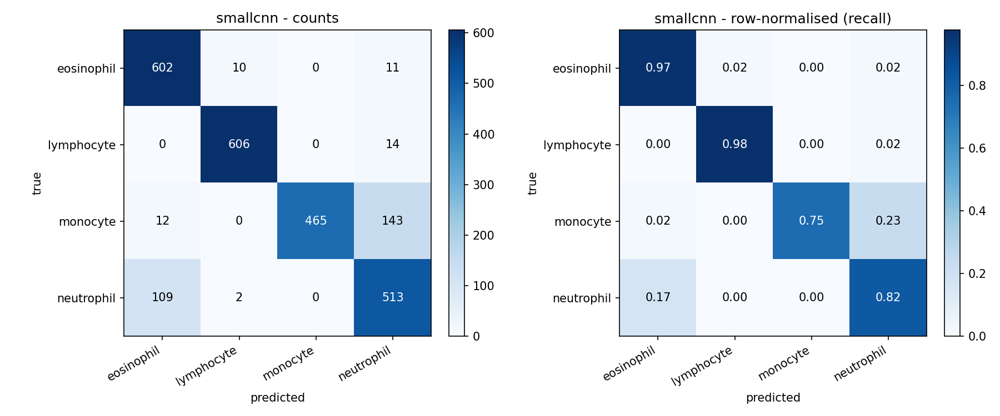

===== densenet169_ft_s42
              precision    recall  f1-score   support

  eosinophil     0.8711    0.8138    0.8415       623
  lymphocyte     0.9952    1.0000    0.9976       620
    monocyte     1.0000    0.7500    0.8571       620
  neutrophil     0.7160    0.9375    0.8119       624

    accuracy                         0.8754      2487
   macro avg     0.8956    0.8753    0.8770      2487
weighted avg     0.8953    0.8754    0.8769      2487



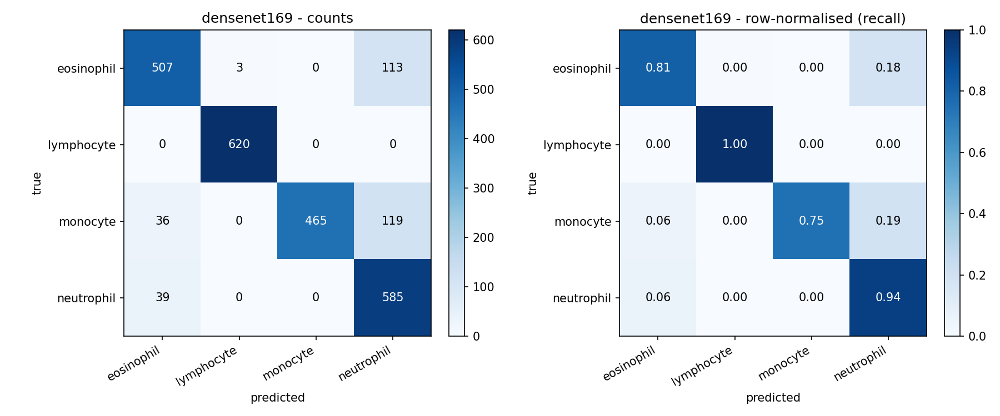

In [16]:
for run in ["smallcnn_scratch_s42", "densenet169_ft_s42"]:
    print("=====", run)
    print(open(f"{EXP}/{run}/eval/classification_report.txt").read())
    display(IPImage(f"{EXP}/{run}/eval/confusion_matrix.png", width=900))

The test set holds only ~113 independent photos. Counting per photo shows the errors come in whole photos:

**Cell 8b · SKIP** — the per-photo code

- **What it does.** Prints `per_photo_table`. It adds the source photo to every test prediction (from the split file) and groups by class and photo: how many copies, and what share of them is correct.
- **What it means for our project.** The same matching that fixed the split also lets us count errors per photo instead of per image.

In [17]:
show(error_analysis.per_photo_table)

`src/error_analysis.py`, line 39
```python
def per_photo_table(pred: pd.DataFrame, spec: dict) -> pd.DataFrame:
    pred = pred.assign(photo=pred.path.map(lambda p: spec[test_key(p)]["source"]), ok=pred.true == pred.pred)
    return (pred.groupby(["true", "photo"]).agg(copies=("ok", "size"), share_correct=("ok", "mean"))
            .reset_index().rename(columns={"true": "class"}))

```

**Cell 8c · STOP · 0:20** — errors come in whole photos

- **What it does.** For both models, counts the test photos per class where all copies are right, all are wrong, or the result is mixed. Then shows the SmallCNN's most confident errors.
- **What it means for our project.** A model tends to get every rotated copy of a photo right, or every copy wrong. For monocytes there are 16 test photos: 13 fully right and 3 fully wrong, in both models. One monocyte photo is worth about 6 points of monocyte recall. So the test set behaves like about 113 independent examples, not 2,487, and the per-class numbers are less certain than the ± suggests. We state this as a limitation.
- **If asked.** Photo counts per class add up to more than 113 because a few photos carry two labels.

===== smallcnn_scratch_s42


,test photos,all copies right,all copies wrong,mixed
class,,,,
eosinophil,35,32,0,3
lymphocyte,17,15,1,1
monocyte,16,13,3,0
neutrophil,64,50,9,5


===== densenet169_ft_s42


,test photos,all copies right,all copies wrong,mixed
class,,,,
eosinophil,35,27,2,6
lymphocyte,17,17,0,0
monocyte,16,13,3,0
neutrophil,64,56,1,7


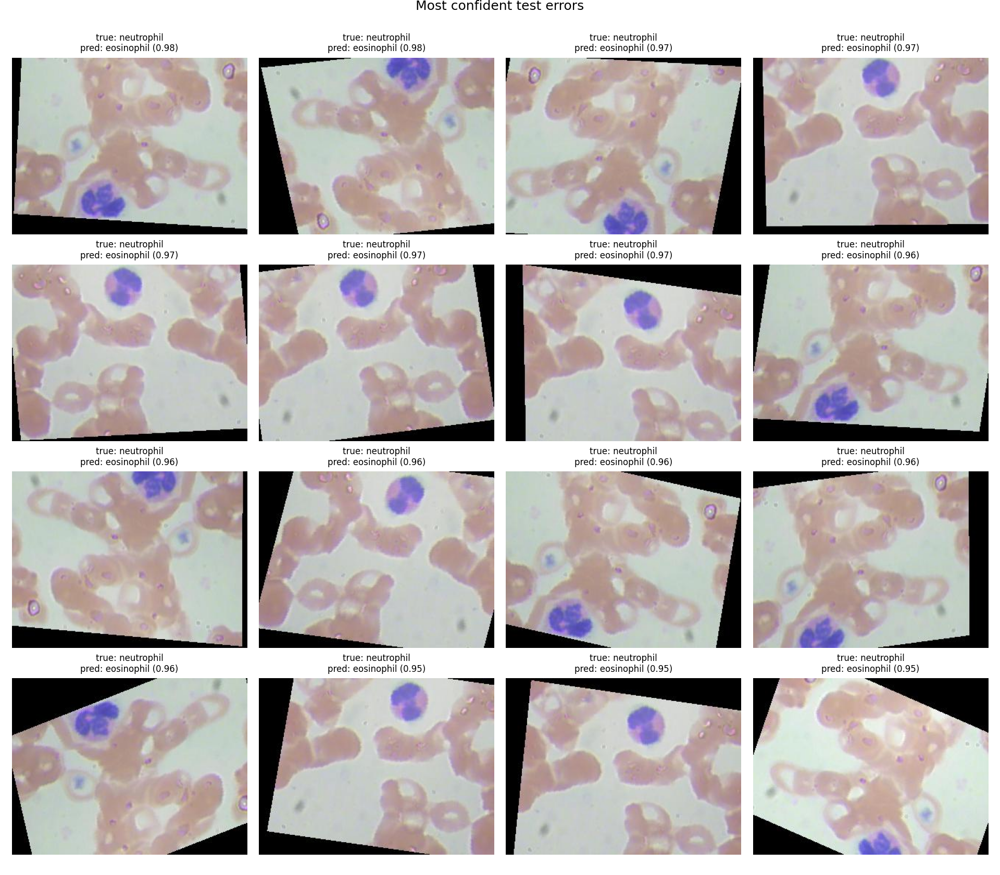

In [18]:
spec = s["images"]
for run in ["smallcnn_scratch_s42", "densenet169_ft_s42"]:
    pred = pd.read_csv(f"{EXP}/{run}/eval/predictions.csv")
    print("=====", run); display(error_analysis.photo_summary(error_analysis.per_photo_table(pred, spec)))
display(IPImage(f"{EXP}/smallcnn_scratch_s42/eval/misclassified.png", width=900))

## 9. Grad-CAM — `src/gradcam.py`

Gradient-weighted activations of the last convolutional stage (Selvaraju et al., 2017). One live example, then the
saved grids: 4 correct (one per class) and 4 confident errors from 4 different photos.

**Cell 9a · SKIP** — the Grad-CAM code

- **What it does.** Prints our `GradCAM` class. A hook stores the output of the last convolutional stage and its gradient for the predicted class. Each channel is weighted by its average gradient, the channels are summed, negative values are removed, and the map is resized to the image and scaled to 0–1.
- **What it means for our project.** Grad-CAM shows which part of the image pushed the network to its answer, so we can check that it looks at the white cell and not at the background.
- **If asked.** `.clone()` is a fix we needed for DenseNet: its next layer changes the stored values in place, which gave wrong heatmaps before.

In [19]:
show(gradcam.GradCAM)

`src/gradcam.py`, line 28
```python
class GradCAM:
    def __init__(self, model: nn.Module, target_layer: nn.Module):
        self.model = model
        self.acts = None
        self.grads = None
        target_layer.register_forward_hook(self._forward_hook)

    def _forward_hook(self, module, inputs, output):
        # clone: DenseNet applies an in-place ReLU right after this layer, which would
        # otherwise overwrite the stored activations
        self.acts = output.detach().clone()
        # tensor hook instead of a module backward hook: works with in-place ReLUs
        output.register_hook(lambda g: setattr(self, "grads", g.detach()))

    def __call__(self, x: torch.Tensor, class_idx: int | None = None):
        """x: (1, 3, H, W). Returns (cam in [0, 1] with shape (H, W), logits)."""
        with torch.enable_grad():
            self.model.zero_grad(set_to_none=True)
            logits = self.model(x)
            if class_idx is None:
                class_idx = int(logits.argmax(dim=1))
            logits[0, class_idx].backward()
        weights = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((weights * self.acts).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.cpu().numpy(), logits.detach()

```

**Cell 9b · STOP · 0:25** — one live heatmap, then the saved examples

- **What it does.** Loads the selected SmallCNN checkpoint with `Predictor`, the same class the demo uses, and classifies one monocyte test image live. Then shows the saved grids for both models: 4 correct examples, one per class, and the 4 most confident errors, each from a different photo.
- **What it means for our project.** The SmallCNN's heatmap sits on the white cell even when the answer is wrong, so its errors are real confusions between similar cell types. DenseNet's heatmap stays in the centre when the white cell is near the edge. Both models are wrong with 0.91–1.00 confidence, which is why calibration is one of our recommendations.
- **If asked.** These are a few chosen examples: illustrations, not proof. If the live example comes out wrong, say so: monocyte is the weakest class.

live: _0_1123.jpeg -> monocyte (1.00)


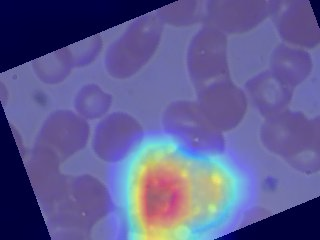

smallcnn_scratch_s42


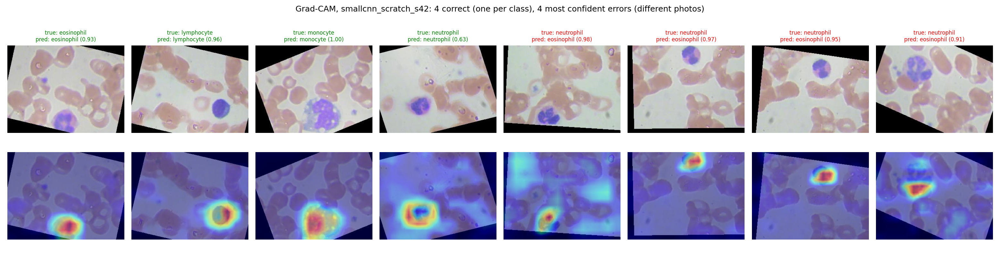

densenet169_ft_s42


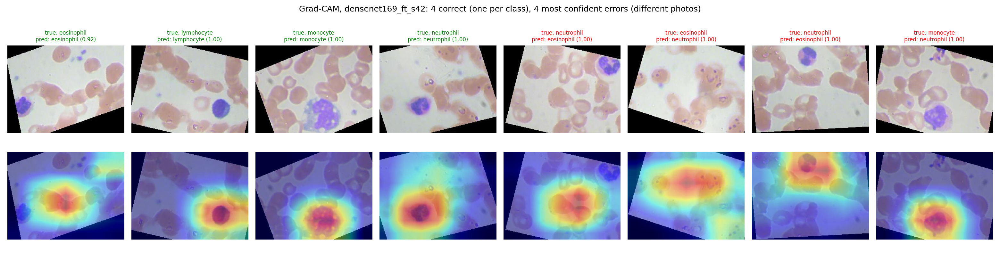

In [20]:
from predictor import Predictor
pr = Predictor(f"{EXP}/smallcnn_scratch_s42/best.pt")
f = sorted(os.listdir(f"{test_dir}/MONOCYTE"))[0]
out = pr.predict(Image.open(f"{test_dir}/MONOCYTE/{f}"))
print("live:", f, "->", out["pred"], f"({out['confidence']:.2f})"); display(out["overlay"])
for run in ["smallcnn_scratch_s42", "densenet169_ft_s42"]:
    p = f"{EXP}/{run}/eval/gradcam_examples.png"
    if os.path.exists(p):
        print(run); display(IPImage(p))

## 10. Ablations (SmallCNN, same recipe, 3 seeds)

Promised at the midterm: augmentation on vs. off. Asked in the feedback: the 4:3 → 1:1 squash. `pad` adds black bars
instead of stretching, so nothing is distorted or cut off.

**Cell 10a · SKIP** — the resize options

- **What it does.** Prints `resize_ops`, the three ways a 320×240 image becomes a 224×224 square: `squash` stretches it, `pad` adds black bars, `crop` cuts the sides.
- **What it means for our project.** The feedback asked whether squashing distorts the cells. This function let us test the alternative by changing one flag and nothing else.
- **If asked.** We did not test `crop`: several misclassified images have the white cell near the left or right edge, and a centre crop would cut it off.

In [21]:
show(data.resize_ops)

`src/data.py`, line 73
```python
def resize_ops(img_size: int, mode: str = "squash") -> list:
    """How the 320x240 (4:3) frame becomes img_size x img_size.

    squash - resize both sides (default, midterm behaviour): keeps the whole frame, stretches it 4:3 -> 1:1
    pad    - add black bars top and bottom to 320x320, then resize: no distortion, nothing lost
             (black matches the corners the Kaggle rotations already have)
    crop   - resize the short side to img_size, centre crop: no distortion, loses ~25% of the width,
             so a white cell near the left/right edge can be cut off
    """
    bilinear = InterpolationMode.BILINEAR
    if mode == "squash":
        return [transforms.Resize((img_size, img_size), interpolation=bilinear)]
    if mode == "pad":
        return [transforms.Lambda(pad_to_square), transforms.Resize((img_size, img_size), interpolation=bilinear)]
    if mode == "crop":
        return [transforms.Resize(img_size, interpolation=bilinear), transforms.CenterCrop(img_size)]
    raise ValueError(f"resize mode must be one of {RESIZE_MODES}, got '{mode}'")

```

**Cell 10b · STOP · 0:20** — ablation results

- **What it does.** Filters the summary table to the three SmallCNN configurations: the baseline, augmentation off, and pad to square.
- **What it means for our project.** Both original choices hold up. Without augmentation, test macro-F1 falls from 0.865 ± 0.015 to 0.827 ± 0.053, and the seed-to-seed spread triples. Pad-to-square has the **best validation accuracy** of any configuration (0.938) but the **lowest test score** of the three (0.796 ± 0.061). Our rule, lowest validation loss, keeps the baseline, and the test set agrees.
- **If asked.** Augmentation is applied to training images only, after the split, so it cannot leak anything into validation or test. Why padding hurts is a hypothesis we did not test: the frame shrinks to 224×168 pixels plus bars, so the white cell gets fewer pixels.

In [22]:
abl = summary[summary.configuration.str.startswith("smallcnn")]
display(abl[["configuration", "seeds", "val loss", "val acc", "test macro-F1", "clean test macro-F1"]])
if len(abl) == 1:
    print("Ablation runs not found yet: run section 4c of colab_quickstart.ipynb first.")

,configuration,seeds,val loss,val acc,test macro-F1,clean test macro-F1
4,"smallcnn (scratch, no augmentation)",3,0.3948 ± 0.1155,0.8586 ± 0.0136,0.8272 ± 0.0527,0.8116 ± 0.0567
5,"smallcnn (scratch, pad resize)",3,0.2769 ± 0.0689,0.9379 ± 0.0137,0.7957 ± 0.0605,0.7798 ± 0.0599
6,smallcnn (scratch),3,0.2248 ± 0.0109,0.9166 ± 0.0080,0.8648 ± 0.0149,0.8514 ± 0.0167


## Limitations

* Validation has few photos per class (4 lymphocyte, 6 monocyte), so it is ~5 points more optimistic than test.
* ± is seed-to-seed spread on one split; the test set's ~113 photos make per-class numbers far less certain.
* Grad-CAM figures are a handful of examples: illustrations, not proof.
* 783 TRAIN-folder images whose source photo could not be identified with confidence were left out.
* Research prototype on one public dataset, not a clinical tool.

## Midterm feedback → where it is answered in this notebook

| Feedback / promise | Answered in |
|---|---|
| Overlap check was not rotation-aware | Section 2 (cells 2a, 2b) |
| Validation was saturated | Section 3 (cell 3b), section 6 |
| Full frozen-backbone run | Sections 6 and 7 |
| EfficientNet-B0 and DenseNet-169 under the same recipe | Sections 4 to 7 |
| One run per model | 3 seeds, sections 5 to 7 |
| Test set once, per-class metrics and confusion matrix | Sections 7 and 8 |
| Augmentation on/off, and the 4:3 squash | Section 10 |